Project Root: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis

========== DATASET LOADED ==========
RFM Dataset Shape: (4338, 4)
Segmentation Dataset Shape: (4338, 5)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,2
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,3
4,12350,310,1,334.40,1



========== MERGED DATA ==========
Merged Dataset Shape: (4338, 5)


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,2
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,3
4,12350,310,1,334.40,1



========== DATA QUALITY CHECKS ==========
Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
Cluster       0
dtype: int64

Duplicate Customer IDs: 0

Unique Customers: 4338

========== CLV CALCULATION ==========


... (5 outputs left out)


========== CUSTOMER SEGMENT CLV ANALYSIS ==========


,Customer_Count,Average_Recency,Average_Frequency,Average_CLV,Total_Revenue,Median_CLV,Customer_Percentage,Revenue_Contribution_Percentage
Cluster,,,,,,,,
0,1377,58.04,1.51,384.22,529065.50,341.36,31.74,5.95
1,938,259.41,1.37,385.39,361494.46,294.18,21.62,4.07
2,571,19.77,15.84,9823.43,5609180.83,4521.49,13.16,63.12
3,1452,46.06,4.21,1644.26,2387468.10,1316.16,33.47,26.86



========== CUSTOMER RETENTION ANALYSIS ==========


,Customer_Count,Average_CLV,Total_Revenue,Customer_Percentage
Customer_Status,,,,
Inactive,1449,712.59,1032542.29,33.4
Recently Active,2889,2718.82,7854666.60,66.6


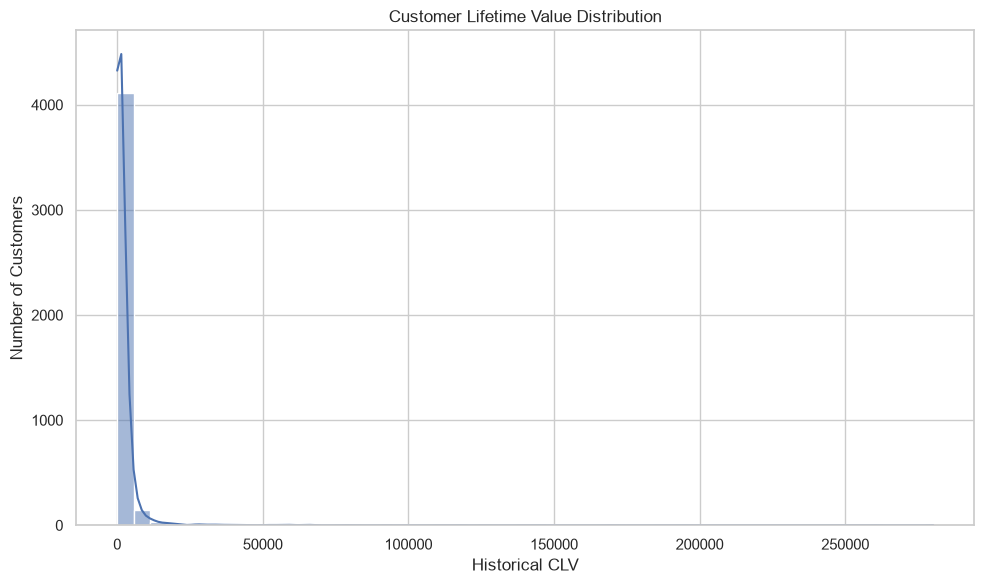

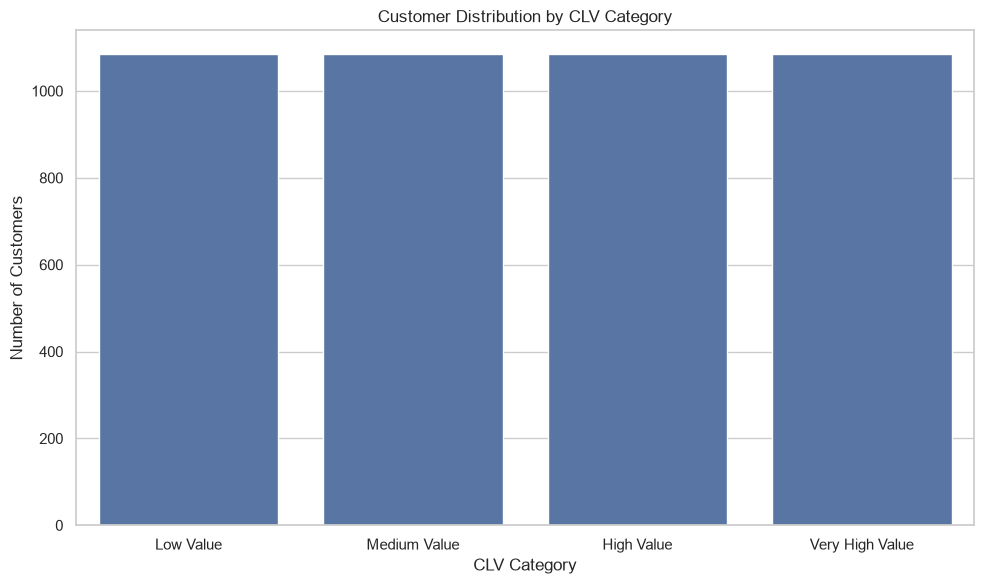

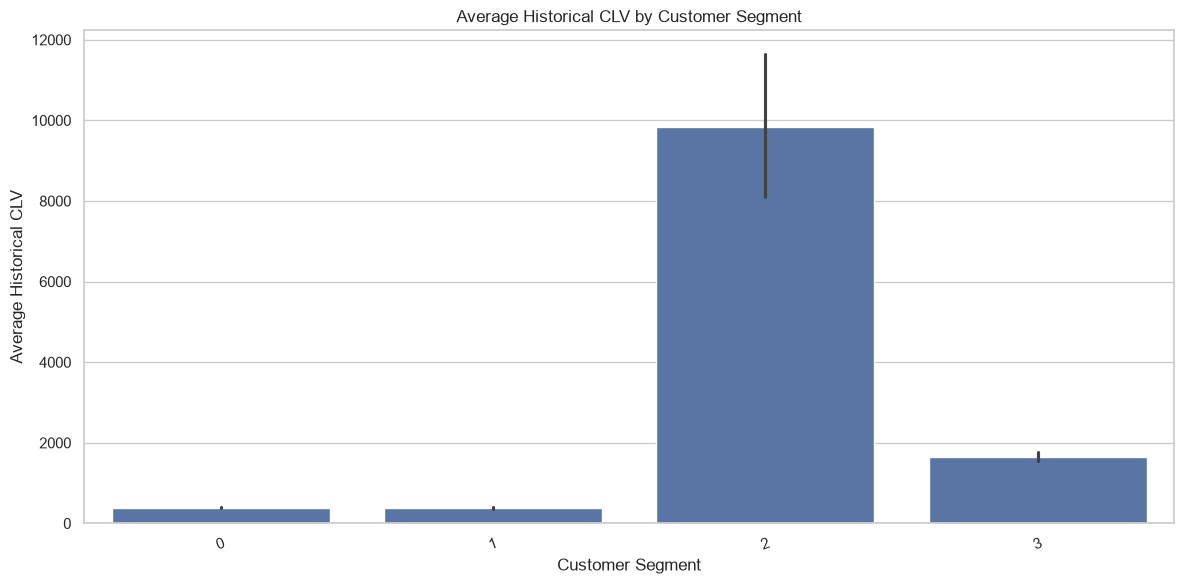

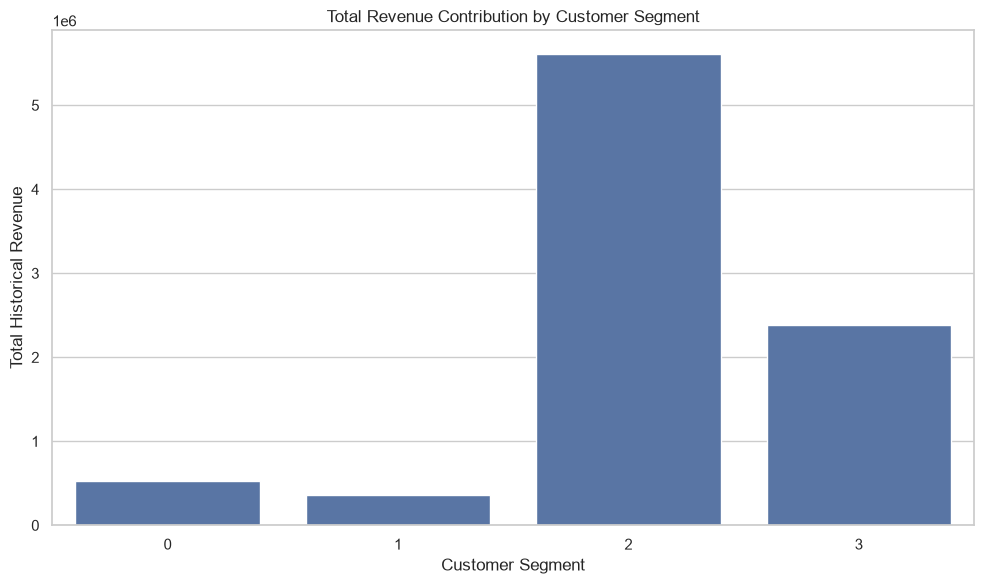

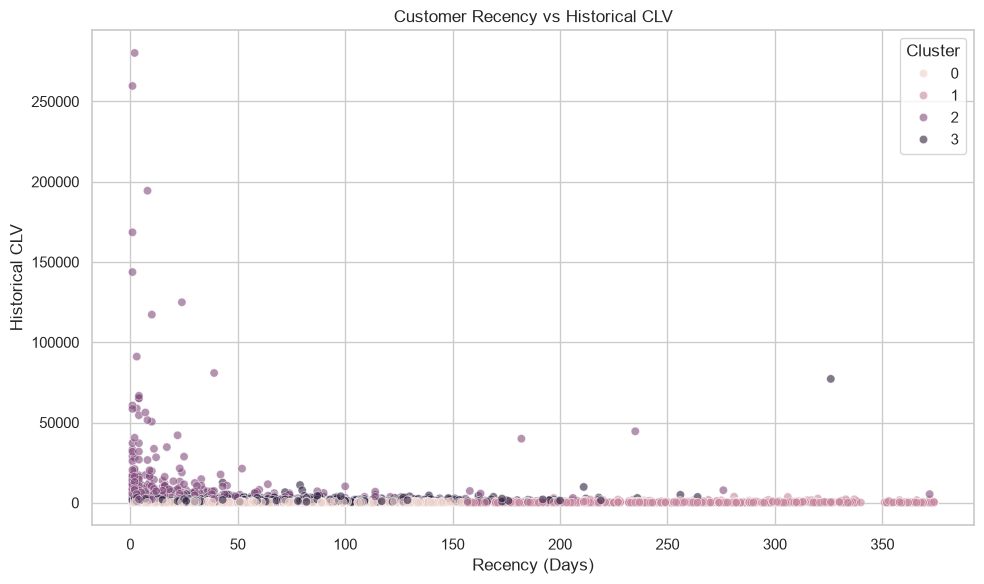


========== BUSINESS INSIGHTS ==========
1. Highest CLV Category: Very High Value
2. Highest Revenue Segment: 2
3. Highest Average CLV Segment: 2
4. Inactive Customer Percentage: 33.4 %
5. Total Historical Revenue: 8887208.89

========== CLV BUSINESS RECOMMENDATIONS ==========


,Customer_Count,Average_CLV,Total_Revenue,Median_CLV,Customer_Percentage,Business_Recommendation
CLV_Category,,,,,,
Low Value,1085,178.03,193166.38,176.50,25.01,Use personalized offers and product bundles to...
Medium Value,1084,461.91,500706.78,446.40,24.99,Improve customer engagement through loyalty pr...
High Value,1084,1066.18,1155744.35,1026.72,24.99,Provide exclusive benefits and encourage custo...
Very High Value,1085,6486.26,7037591.38,3049.88,25.01,"Focus on VIP rewards, premium services and lon..."



All CLV Datasets Exported Successfully!

Summary Report Saved Successfully!
Total Customers: 4338
Unique Customer IDs: 4338
Missing Values: 0
Duplicate Customer IDs: 0
Total CLV: 8887208.89


In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

project_root = Path.cwd()

if not (project_root / "Data").exists():
    project_root = Path.cwd().parent

data_path = project_root / "Data" / "processed"
reports_path = project_root / "reports"

data_path.mkdir(parents=True, exist_ok=True)
reports_path.mkdir(parents=True, exist_ok=True)

print("Project Root:", project_root)

rfm_path = data_path / "customer_rfm.csv"
segments_path = data_path / "customer_segments.csv"

if not rfm_path.exists():
    raise FileNotFoundError("customer_rfm.csv not found!")

if not segments_path.exists():
    raise FileNotFoundError("customer_segments.csv not found!")

rfm = pd.read_csv(rfm_path)
segments = pd.read_csv(segments_path)

print("\n========== DATASET LOADED ==========")
print("RFM Dataset Shape:", rfm.shape)
print("Segmentation Dataset Shape:", segments.shape)

display(rfm.head())
display(segments.head())

segment_columns = ["CustomerID", "Cluster"]

if "Customer_Segment" in segments.columns:
    segment_columns.append("Customer_Segment")

segments_clean = segments[segment_columns].copy()


segments_clean = segments_clean.drop_duplicates(
    subset="CustomerID"
)

clv_data = rfm.merge(
    segments_clean,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

print("\n========== MERGED DATA ==========")
print("Merged Dataset Shape:", clv_data.shape)

display(clv_data.head())

print("\n========== DATA QUALITY CHECKS ==========")

print("Missing Values:")
print(clv_data.isnull().sum())

print("\nDuplicate Customer IDs:",
      clv_data["CustomerID"].duplicated().sum())

print("\nUnique Customers:",
      clv_data["CustomerID"].nunique())

clv_data["Historical_CLV"] = clv_data["Monetary"]


clv_data["Average_Order_Value"] = (
    clv_data["Monetary"]
    / clv_data["Frequency"].replace(0, np.nan)
)

clv_data["Average_Order_Value"] = (
    clv_data["Average_Order_Value"].fillna(0)
)

clv_data["CLV_Category"] = pd.qcut(
    clv_data["Historical_CLV"].rank(method="first"),
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ]
)

print("\n========== CLV CALCULATION ==========")

display(
    clv_data[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "Historical_CLV",
            "Average_Order_Value",
            "CLV_Category"
        ]
    ].head(10)
)

total_customers = clv_data["CustomerID"].nunique()

total_revenue = clv_data["Historical_CLV"].sum()

average_clv = clv_data["Historical_CLV"].mean()

median_clv = clv_data["Historical_CLV"].median()

average_order_value = clv_data["Average_Order_Value"].mean()

average_frequency = clv_data["Frequency"].mean()

print("\n========== OVERALL CLV STATISTICS ==========")

print("Total Customers:", total_customers)

print("Total Historical Revenue:",
      round(total_revenue, 2))

print("Average Historical CLV:",
      round(average_clv, 2))

print("Median Historical CLV:",
      round(median_clv, 2))

print("Average Order Value:",
      round(average_order_value, 2))

print("Average Purchase Frequency:",
      round(average_frequency, 2))


customer_ranking = clv_data.sort_values(
    by="Historical_CLV",
    ascending=False
).copy()

customer_ranking["CLV_Rank"] = (
    customer_ranking["Historical_CLV"]
    .rank(method="min", ascending=False)
    .astype(int)
)

print("\n========== TOP 10 HIGH-VALUE CUSTOMERS ==========")

display(
    customer_ranking[
        [
            "CustomerID",
            "Frequency",
            "Monetary",
            "Historical_CLV",
            "CLV_Rank",
            "CLV_Category"
        ]
    ].head(10)
)

clv_category_analysis = clv_data.groupby(
    "CLV_Category",
    observed=False
).agg(
    Customer_Count=("CustomerID", "count"),
    Average_CLV=("Historical_CLV", "mean"),
    Total_Revenue=("Historical_CLV", "sum"),
    Median_CLV=("Historical_CLV", "median")
).round(2)

clv_category_analysis["Customer_Percentage"] = (
    clv_category_analysis["Customer_Count"]
    / total_customers
    * 100
).round(2)

print("\n========== CLV CATEGORY ANALYSIS ==========")

display(clv_category_analysis)

segment_analysis = clv_data.groupby(
    "Customer_Segment"
    if "Customer_Segment" in clv_data.columns
    else "Cluster"
).agg(
    Customer_Count=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_CLV=("Historical_CLV", "mean"),
    Total_Revenue=("Historical_CLV", "sum"),
    Median_CLV=("Historical_CLV", "median")
).round(2)

segment_analysis["Customer_Percentage"] = (
    segment_analysis["Customer_Count"]
    / total_customers
    * 100
).round(2)

segment_analysis["Revenue_Contribution_Percentage"] = (
    segment_analysis["Total_Revenue"]
    / total_revenue
    * 100
).round(2)

print("\n========== CUSTOMER SEGMENT CLV ANALYSIS ==========")

display(segment_analysis)

clv_data["Customer_Status"] = np.where(
    clv_data["Recency"] > 90,
    "Inactive",
    "Recently Active"
)

retention_analysis = clv_data.groupby(
    "Customer_Status"
).agg(
    Customer_Count=("CustomerID", "count"),
    Average_CLV=("Historical_CLV", "mean"),
    Total_Revenue=("Historical_CLV", "sum")
).round(2)

retention_analysis["Customer_Percentage"] = (
    retention_analysis["Customer_Count"]
    / total_customers
    * 100
).round(2)

print("\n========== CUSTOMER RETENTION ANALYSIS ==========")

display(retention_analysis)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=clv_data,
    x="Historical_CLV",
    bins=50,
    kde=True
)

plt.title("Customer Lifetime Value Distribution")
plt.xlabel("Historical CLV")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    reports_path / "week3_clv_distribution.png",
    dpi=300
)

plt.show()

plt.figure(figsize=(10, 6))

sns.countplot(
    data=clv_data,
    x="CLV_Category",
    order=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ]
)

plt.title("Customer Distribution by CLV Category")
plt.xlabel("CLV Category")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    reports_path / "week3_clv_category_distribution.png",
    dpi=300
)

plt.show()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=clv_data,
    x="Customer_Segment"
    if "Customer_Segment" in clv_data.columns
    else "Cluster",
    y="Historical_CLV",
    estimator="mean"
)

plt.title("Average Historical CLV by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Historical CLV")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    reports_path / "week3_segment_average_clv.png",
    dpi=300
)

plt.show()


plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_analysis.index.astype(str),
    y=segment_analysis["Total_Revenue"].values
)

plt.title("Total Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Historical Revenue")

plt.tight_layout()

plt.savefig(
    reports_path / "week3_segment_revenue.png",
    dpi=300
)

plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clv_data,
    x="Recency",
    y="Historical_CLV",
    hue="Customer_Segment"
    if "Customer_Segment" in clv_data.columns
    else "Cluster",
    alpha=0.6
)

plt.title("Customer Recency vs Historical CLV")
plt.xlabel("Recency (Days)")
plt.ylabel("Historical CLV")

plt.tight_layout()

plt.savefig(
    reports_path / "week3_recency_vs_clv.png",
    dpi=300
)

plt.show()


highest_clv_category = (
    clv_category_analysis["Average_CLV"].idxmax()
)

highest_revenue_segment = (
    segment_analysis["Total_Revenue"].idxmax()
)

highest_avg_clv_segment = (
    segment_analysis["Average_CLV"].idxmax()
)

inactive_percentage = (
    retention_analysis.loc[
        "Inactive",
        "Customer_Percentage"
    ]
    if "Inactive" in retention_analysis.index
    else 0
)

print("\n========== BUSINESS INSIGHTS ==========")

print(
    "1. Highest CLV Category:",
    highest_clv_category
)

print(
    "2. Highest Revenue Segment:",
    highest_revenue_segment
)

print(
    "3. Highest Average CLV Segment:",
    highest_avg_clv_segment
)

print(
    "4. Inactive Customer Percentage:",
    round(inactive_percentage, 2),
    "%"
)

print(
    "5. Total Historical Revenue:",
    round(total_revenue, 2)
)

business_recommendations = {
    "Low Value":
        "Use personalized offers and product bundles to encourage "
        "repeat purchases.",

    "Medium Value":
        "Improve customer engagement through loyalty programs "
        "and targeted recommendations.",

    "High Value":
        "Provide exclusive benefits and encourage customers "
        "to increase purchase frequency.",

    "Very High Value":
        "Focus on VIP rewards, premium services and long-term "
        "customer relationships."
}

clv_category_analysis["Business_Recommendation"] = (
    clv_category_analysis.index.map(
        business_recommendations
    )
)

print("\n========== CLV BUSINESS RECOMMENDATIONS ==========")

display(clv_category_analysis)


clv_data.to_csv(
    data_path / "customer_clv_analysis.csv",
    index=False
)

customer_ranking.to_csv(
    data_path / "customer_clv_ranking.csv",
    index=False
)

clv_category_analysis.to_csv(
    data_path / "clv_category_analysis.csv"
)

segment_analysis.to_csv(
    data_path / "segment_clv_analysis.csv"
)

retention_analysis.to_csv(
    data_path / "customer_retention_analysis.csv"
)

print("\nAll CLV Datasets Exported Successfully!")

report = f"""
# Customer Lifetime Value Analysis

## Objective

To analyze historical customer lifetime value, identify high-value
customers, evaluate customer segments and provide actionable
business recommendations.

## Dataset

- Total Customers: {total_customers}
- Total Historical Revenue: {total_revenue:.2f}
- Average Historical CLV: {average_clv:.2f}
- Median Historical CLV: {median_clv:.2f}
- Average Order Value: {average_order_value:.2f}
- Average Purchase Frequency: {average_frequency:.2f}

## CLV Analysis

The analysis calculated historical customer value using total
customer spending.

## CLV Categories

{clv_category_analysis.to_string()}

## Customer Segment Analysis

{segment_analysis.to_string()}

## Customer Retention Analysis

{retention_analysis.to_string()}

## Key Business Insights

- Highest CLV Category: {highest_clv_category}
- Highest Revenue Segment: {highest_revenue_segment}
- Highest Average CLV Segment: {highest_avg_clv_segment}
- Inactive Customer Percentage: {inactive_percentage:.2f}%

## Business Recommendations

- Reward high-value customers with exclusive benefits.
- Encourage low-value customers to make repeat purchases.
- Re-engage inactive customers through personalized campaigns.
- Improve customer retention and long-term relationships.

## Important Limitation

This analysis uses historical spending as a CLV measure.
It does not predict future customer revenue or profitability.

The dataset is based on retail transactions and should not be
described as actual fintech customer data.

## Week 3 Deliverables

- Historical CLV calculation
- Customer CLV ranking
- CLV category analysis
- Segment-wise CLV analysis
- Customer retention analysis
- Business insights
- Business recommendations
- Five visualizations
- Exported CSV datasets
- Week 3 summary report
"""

with open(
    reports_path / "week3_summary.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("\nSummary Report Saved Successfully!")


print("Total Customers:", len(clv_data))

print(
    "Unique Customer IDs:",
    clv_data["CustomerID"].nunique()
)

print(
    "Missing Values:",
    clv_data.isnull().sum().sum()
)

print(
    "Duplicate Customer IDs:",
    clv_data["CustomerID"].duplicated().sum()
)

print(
    "Total CLV:",
    round(clv_data["Historical_CLV"].sum(), 2)
)

assert len(clv_data) == len(rfm)

assert clv_data["CustomerID"].is_unique

assert clv_data["Historical_CLV"].notnull().all()

assert clv_data["Historical_CLV"].ge(0).all()

assert clv_data.isnull().sum().sum() == 0



RFM Dataset Shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


Features scaled successfully: (4338, 3)

K=3 vs K=4 COMPARISON


,K,Inertia,Silhouette_Score
0,3,4299.07,0.4157
1,4,3243.03,0.3795


Selected Final K: 3

Final clustering completed!
Number of clusters: 3

FINAL CLUSTER PROFILES


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percentage
Cluster,,,,,,,,
0,1320,30.10,9.84,5492.04,17.0,7.0,2570.50,30.43
1,981,255.11,1.39,397.17,253.0,1.0,290.51,22.61
2,2037,54.70,2.05,612.71,45.0,2.0,508.80,46.96



BUSINESS PERSONAS


,Customer_Count,Customer_Percentage,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Segment
Cluster,,,,,,
0,1320,30.43,30.10,9.84,5492.04,Champions / High-Value Customers
1,981,22.61,255.11,1.39,397.17,At-Risk / Dormant Customers
2,2037,46.96,54.70,2.05,612.71,Recent / Occasional Customers



SEGMENT-WISE BUSINESS RECOMMENDATIONS


,Customer_Segment,Business_Recommendation
Cluster,,
0,Champions / High-Value Customers,"Reward loyal customers with VIP benefits, excl..."
1,At-Risk / Dormant Customers,"Run win-back campaigns, personalized discounts..."
2,Recent / Occasional Customers,NaN


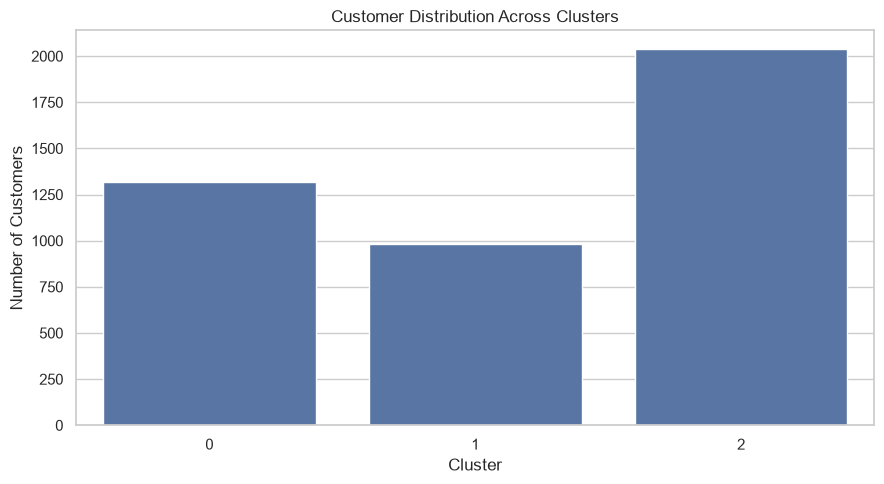

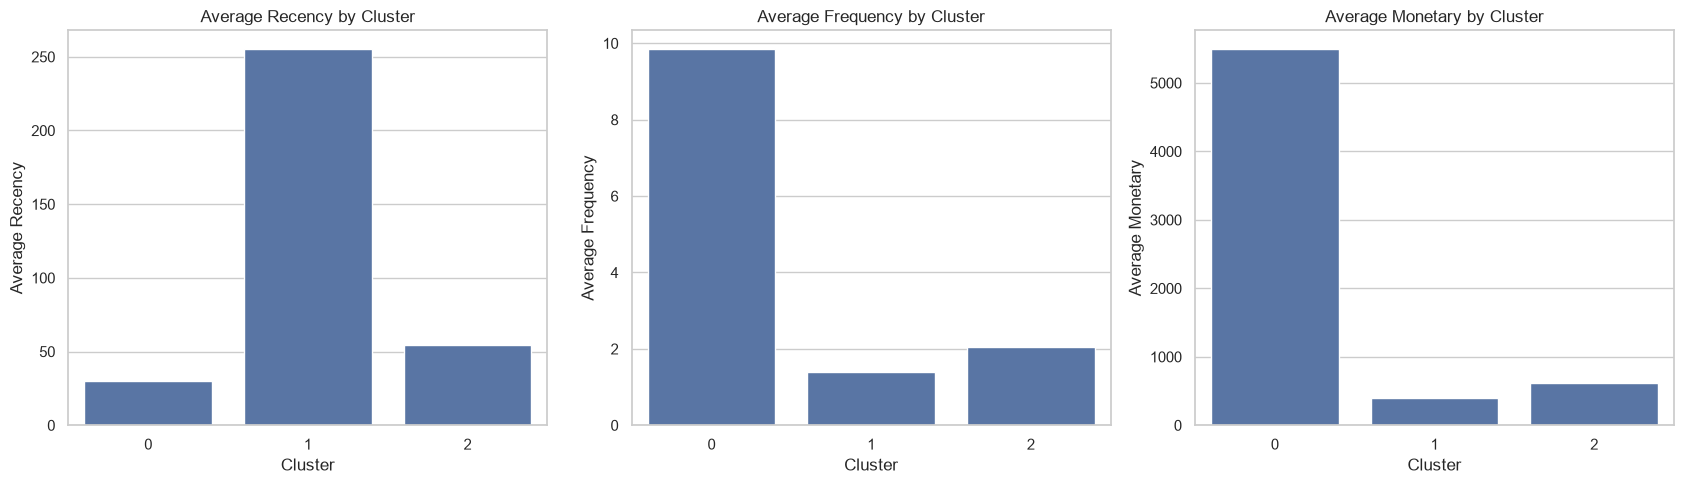

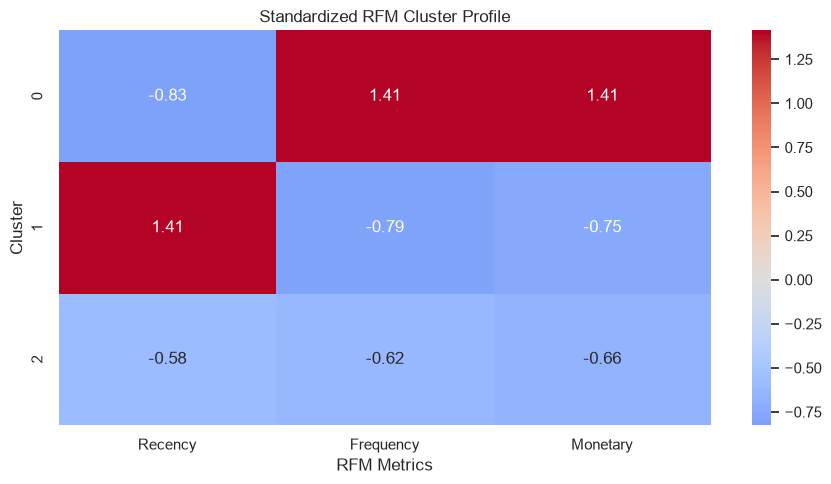

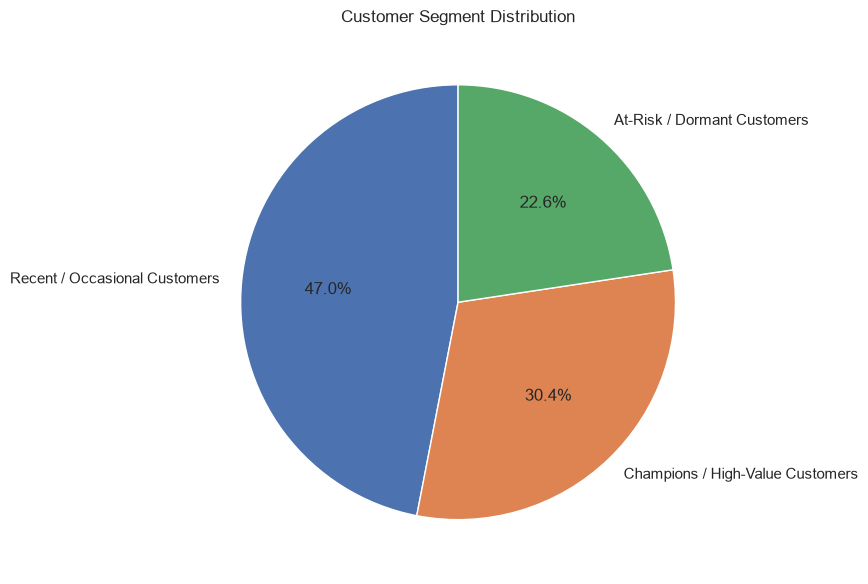

Final datasets exported successfully!
Total Customers: 4338
Selected K: 3
Total Clusters: 3
Missing Values: 0
Duplicate Customer IDs: 0
Cluster Count Total: 4338

ALL VALIDATION CHECKS PASSED!

Summary report saved successfully!


In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

project_path = Path.cwd()

data_path = project_path / "Data" / "processed"
reports_path = project_path / "reports"

data_path.mkdir(parents=True, exist_ok=True)
reports_path.mkdir(parents=True, exist_ok=True)

rfm = pd.read_csv(data_path / "customer_rfm.csv")

print("RFM Dataset Shape:", rfm.shape)
display(rfm.head())

rfm_model = rfm.copy()

rfm_model["Frequency_Log"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary_Log"] = np.log1p(rfm_model["Monetary"])

features = ["Recency", "Frequency_Log", "Monetary_Log"]

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_model[features])

print("Features scaled successfully:", X_scaled.shape)

comparison_results = []

for k in [3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    comparison_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette_Score": round(score, 4)
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nK=3 vs K=4 COMPARISON")
display(comparison_df)

comparison_df.to_csv(
    data_path / "k_comparison.csv",
    index=False
)

final_k = int(
    comparison_df.loc[
        comparison_df["Silhouette_Score"].idxmax(), "K"
    ]
)

print("Selected Final K:", final_k)

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

rfm_final = rfm.copy()
rfm_final["Cluster"] = kmeans_final.fit_predict(X_scaled)

print("\nFinal clustering completed!")
print("Number of clusters:", rfm_final["Cluster"].nunique())


cluster_profiles = rfm_final.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

cluster_profiles["Customer_Percentage"] = (
    cluster_profiles["Customer_Count"] / len(rfm_final) * 100
).round(2)

print("\nFINAL CLUSTER PROFILES")
display(cluster_profiles)

profiles_for_personas = cluster_profiles.copy()

monetary_rank = profiles_for_personas["Avg_Monetary"].sort_values(
    ascending=False
)

champions_cluster = monetary_rank.index[0]

remaining_clusters = [
    cluster for cluster in profiles_for_personas.index
    if cluster != champions_cluster
]

personas = {
    champions_cluster: "Champions / High-Value Customers"
}

if remaining_clusters:
    loyal_cluster = (
        profiles_for_personas.loc[remaining_clusters, "Avg_Frequency"]
        .idxmax()
    )
    personas[loyal_cluster] = "Recent / Occasional Customers"

    for cluster in remaining_clusters:
        if cluster == loyal_cluster:
            continue

        recency = profiles_for_personas.loc[
            cluster, "Avg_Recency"
        ]

        if recency >= profiles_for_personas["Avg_Recency"].median():
            personas[cluster] = "At-Risk / Dormant Customers"
        else:
            personas[cluster] = "Occasional / Low-Value Customers"

cluster_profiles["Customer_Segment"] = [
    personas[cluster] for cluster in cluster_profiles.index
]

rfm_final["Customer_Segment"] = rfm_final["Cluster"].map(personas)

print("\nBUSINESS PERSONAS")
display(
    cluster_profiles[
        [
            "Customer_Count",
            "Customer_Percentage",
            "Avg_Recency",
            "Avg_Frequency",
            "Avg_Monetary",
            "Customer_Segment"
        ]
    ]
)


recommendations = {
    "Champions / High-Value Customers":
        "Reward loyal customers with VIP benefits, exclusive offers and early access.",

    "Loyal / Regular Customers":
        "Use loyalty points, membership benefits and personalized product recommendations.",

    "At-Risk / Dormant Customers":
        "Run win-back campaigns, personalized discounts and re-engagement emails.",

    "Occasional / Low-Value Customers":
        "Encourage repeat purchases through bundles, recommendations and limited-time offers."
}

cluster_profiles["Business_Recommendation"] = (
    cluster_profiles["Customer_Segment"].map(recommendations)
)

print("\nSEGMENT-WISE BUSINESS RECOMMENDATIONS")
display(
    cluster_profiles[
        ["Customer_Segment", "Business_Recommendation"]
    ]
)


plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm_final,
    x="Cluster",
    order=sorted(rfm_final["Cluster"].unique())
)

plt.title("Customer Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(reports_path / "final_cluster_distribution.png", dpi=300)
plt.show()


avg_profile = rfm_final.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(
    axes, ["Recency", "Frequency", "Monetary"]
):
    sns.barplot(
        x=avg_profile.index.astype(str),
        y=avg_profile[column].values,
        ax=ax
    )
    ax.set_title(f"Average {column} by Cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(f"Average {column}")

plt.tight_layout()
plt.savefig(reports_path / "final_rfm_cluster_profiles.png", dpi=300)
plt.show()


heatmap_data = avg_profile.copy()

heatmap_scaled = (
    heatmap_data - heatmap_data.mean()
) / heatmap_data.std(ddof=0)

plt.figure(figsize=(9, 5))

sns.heatmap(
    heatmap_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Standardized RFM Cluster Profile")
plt.xlabel("RFM Metrics")
plt.ylabel("Cluster")
plt.tight_layout()
plt.savefig(reports_path / "final_cluster_heatmap.png", dpi=300)
plt.show()


segment_counts = rfm_final["Customer_Segment"].value_counts()

plt.figure(figsize=(9, 6))

plt.pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segment Distribution")
plt.tight_layout()
plt.savefig(reports_path / "customer_segment_percentage.png", dpi=300)
plt.show()


rfm_final.to_csv(
    data_path / "customer_segments.csv",
    index=False
)

cluster_profiles.to_csv(
    data_path / "final_cluster_profiles.csv"
)

print("Final datasets exported successfully!")


print("Total Customers:", len(rfm_final))
print("Selected K:", final_k)
print("Total Clusters:", rfm_final["Cluster"].nunique())
print("Missing Values:", rfm_final.isnull().sum().sum())
print("Duplicate Customer IDs:", rfm_final["CustomerID"].duplicated().sum())
print(
    "Cluster Count Total:",
    cluster_profiles["Customer_Count"].sum()
)

assert len(rfm_final) == len(rfm)
assert rfm_final["Cluster"].nunique() == final_k
assert rfm_final["CustomerID"].is_unique
assert rfm_final.isnull().sum().sum() == 0
assert cluster_profiles["Customer_Count"].sum() == len(rfm_final)

print("\nALL VALIDATION CHECKS PASSED!")


best_silhouette = comparison_df["Silhouette_Score"].max()

report = f"""

## Objective
To perform Exploratory Data Analysis (EDA), apply K-Means
clustering, and identify meaningful customer segments using RFM.

## Dataset
- Total customers analyzed: {len(rfm_final)}
- RFM features: Recency, Frequency, Monetary
- Clustering algorithm: K-Means
- Selected number of clusters: {final_k}
- Best silhouette score among K=3 and K=4: {best_silhouette}

## K Comparison

{comparison_df.to_string(index=False)}

## Final Customer Segments

{cluster_profiles.to_string()}

## Business Recommendations

{cluster_profiles[["Customer_Segment", "Business_Recommendation"]].to_string()}

## Key Interpretation
- Lower Recency indicates a more recent purchase.
- Higher Frequency indicates more repeat purchases.
- Higher Monetary indicates higher customer spending.
- Champions are the highest-value customers in the selected clustering.
- At-risk customers may need re-engagement campaigns.

## Important Dataset Limitation
The UCI Online Retail dataset represents retail transactions,
not fintech transactions. The RFM and clustering techniques
demonstrated here can be adapted to fintech data, but this
analysis must not be described as actual fintech customer data.

## Week 2 Deliverables
- EDA and RFM analysis
- K-Means clustering
- K comparison
- Cluster profiles
- Customer personas
- Business recommendations
- Visualizations
- Exported segmentation datasets
"""

with open(
    reports_path / "week2_summary.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("\nSummary report saved successfully!")


All libraries imported successfully!

========== DATASET LOADED ==========
Dataset Shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40



========== DATASET INFORMATION ==========
<class 'pandas.DataFrame'>
RangeIndex: 4338 entries, 0 to 4337
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CustomerID  4338 non-null   int64  
 1   Recency     4338 non-null   int64  
 2   Frequency   4338 non-null   int64  
 3   Monetary    4338 non-null   float64
dtypes: float64(1), int64(3)
memory usage: 135.7 KB

========== STATISTICAL SUMMARY ==========


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000



========== MISSING VALUES ==========
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate Customer IDs: 0
Unique Customers: 4338


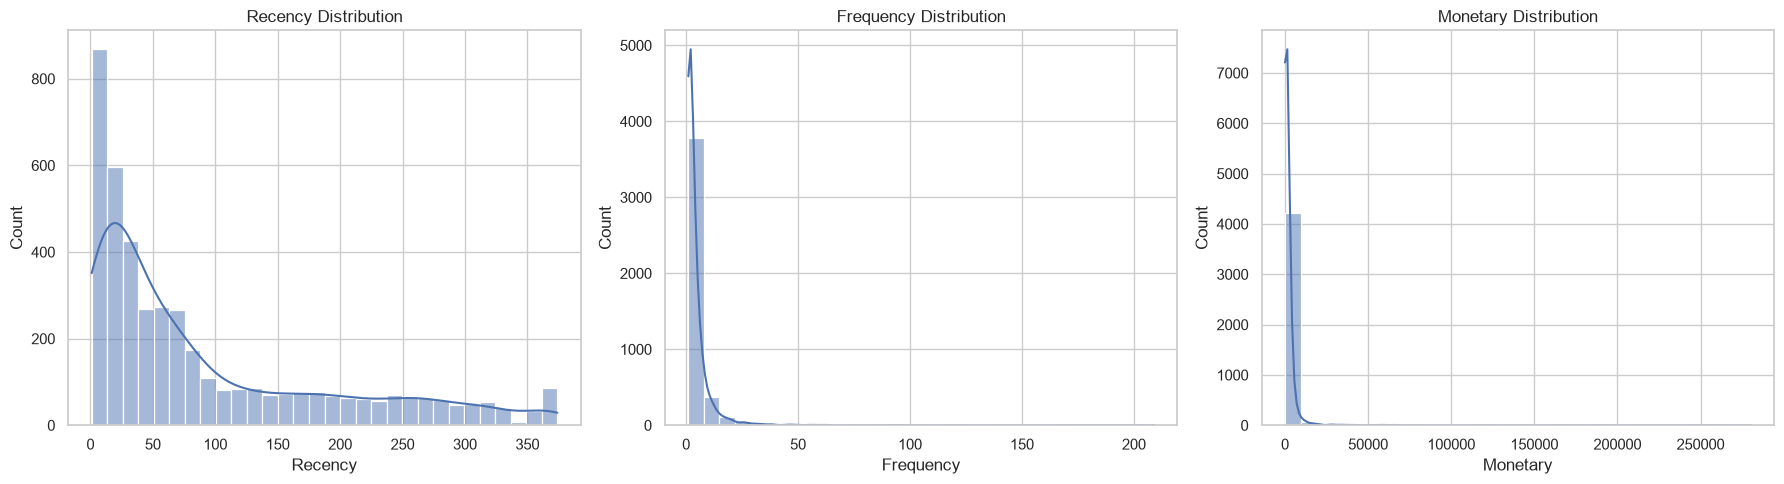

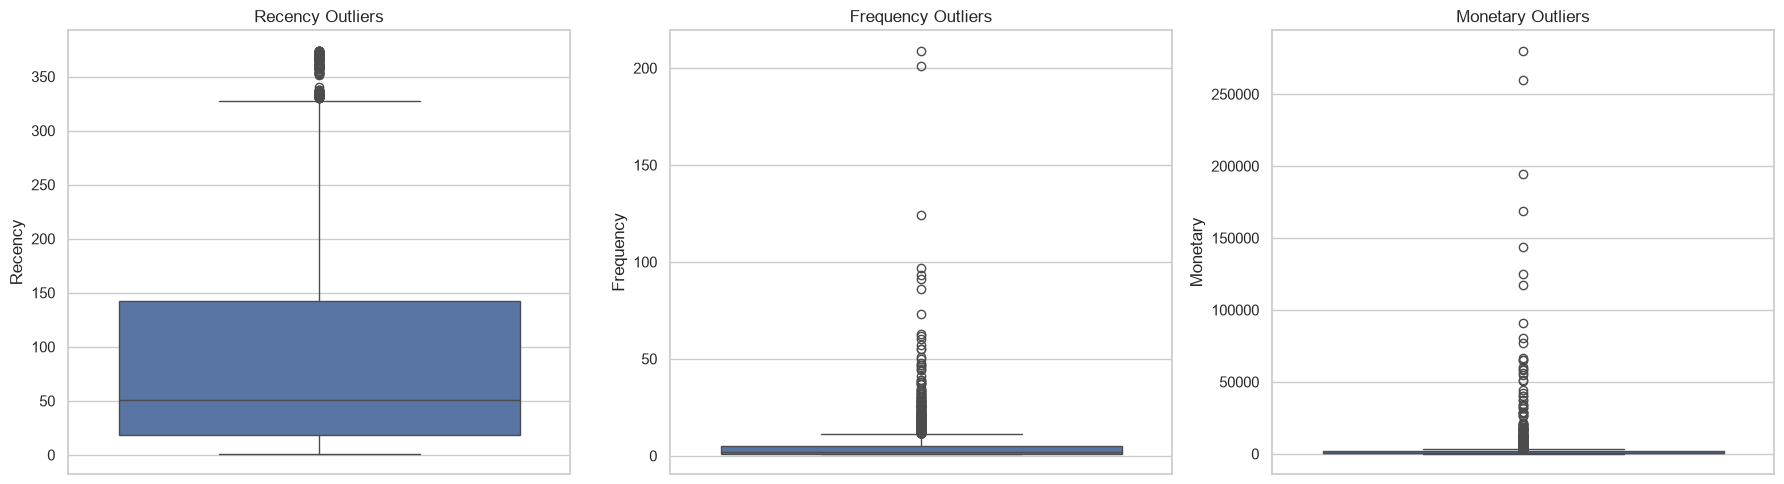

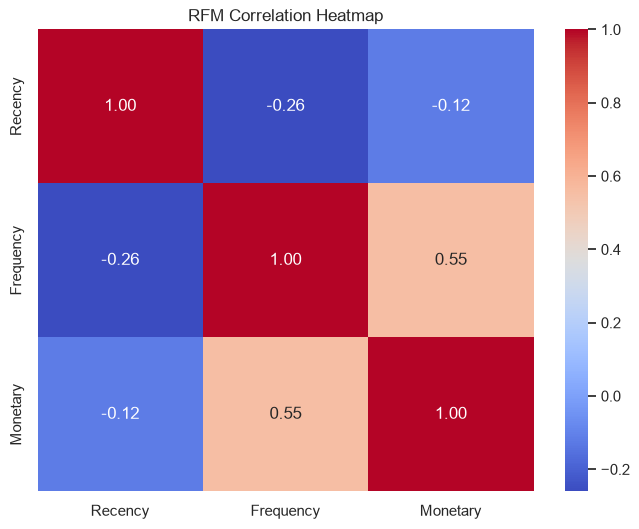


Selected Features: ['Recency', 'Frequency_Log', 'Monetary_Log']
Model Dataset Shape: (4338, 3)


,Recency,Frequency_Log,Monetary_Log
0,326,0.693147,11.253955
1,2,2.079442,8.368925
2,75,1.609438,7.494564
3,19,0.693147,7.472245
4,310,0.693147,5.815324



Feature Scaling Completed!
Scaled Data Shape: (4338, 3)

Elbow Method Completed!


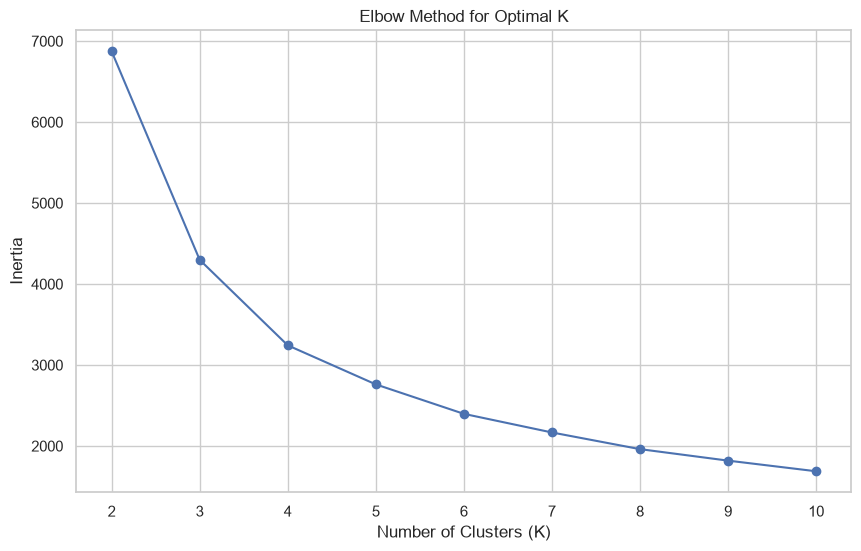

K = 2, Silhouette Score = 0.4062
K = 3, Silhouette Score = 0.4157
K = 4, Silhouette Score = 0.3795
K = 5, Silhouette Score = 0.3435
K = 6, Silhouette Score = 0.3299
K = 7, Silhouette Score = 0.3008
K = 8, Silhouette Score = 0.2999
K = 9, Silhouette Score = 0.2828
K = 10, Silhouette Score = 0.2819


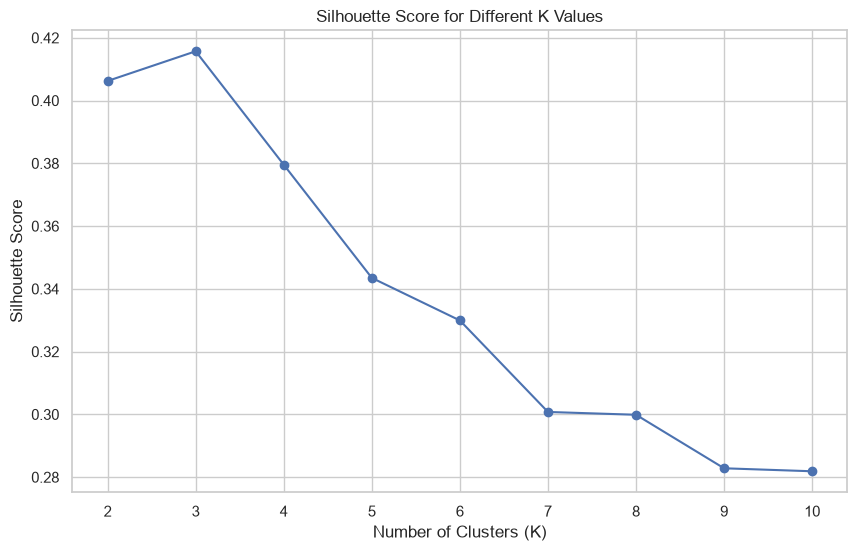


K-Means Clustering Completed!
Number of Clusters: 4

Cluster Distribution:
Cluster
0    1377
1     938
2     571
3    1452
Name: count, dtype: int64


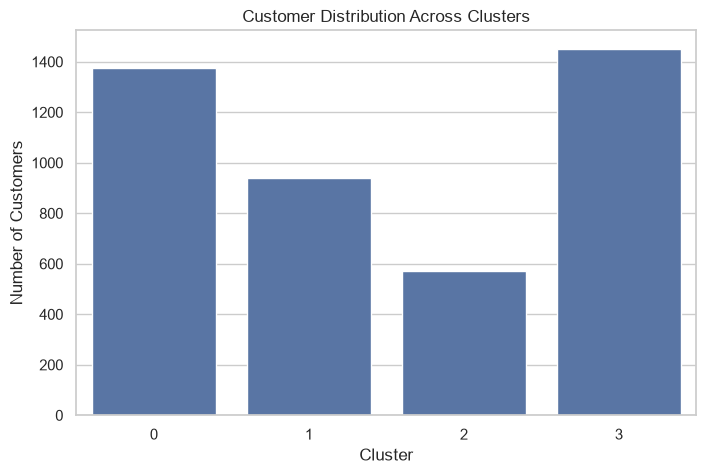


========== CLUSTER PROFILE ==========


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percentage
Cluster,,,,,,,,
0,1377,58.04,1.51,384.22,51.0,1.0,341.36,31.74
1,938,259.41,1.37,385.39,255.0,1.0,294.18,21.62
2,571,19.77,15.84,9823.43,10.0,11.0,4521.49,13.16
3,1452,46.06,4.21,1644.26,31.0,4.0,1316.16,33.47


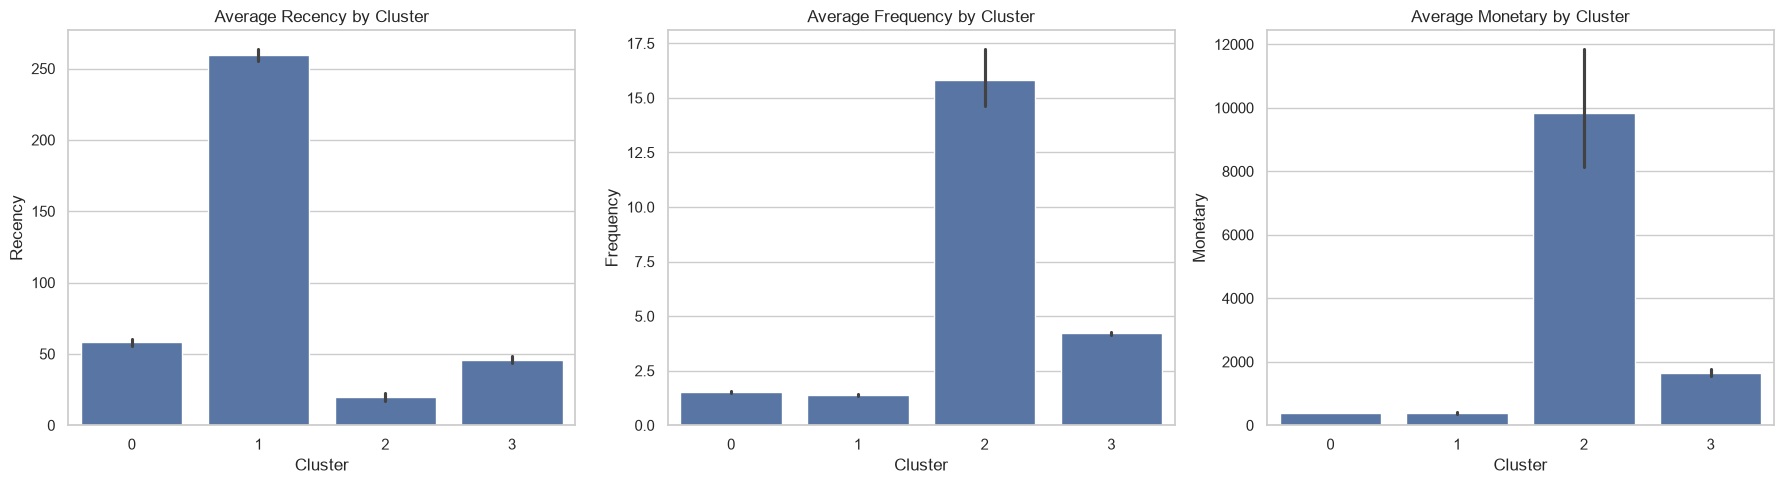

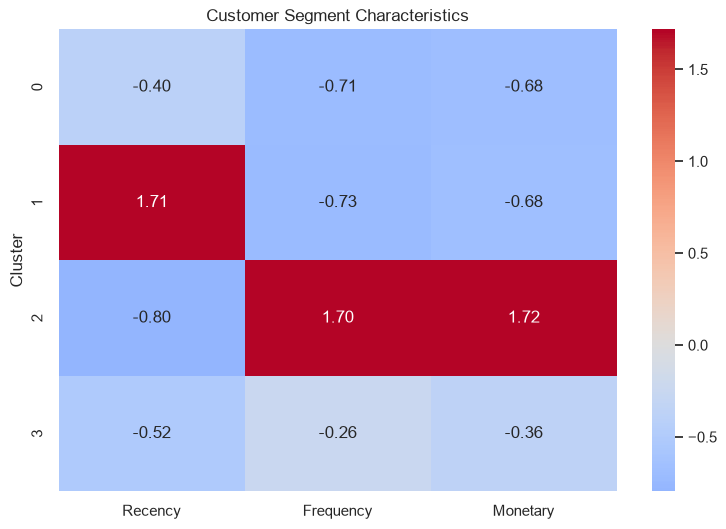


========== FINAL SEGMENTATION DATASET ==========


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,2
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,3
4,12350,310,1,334.40,1
5,12352,36,8,2506.04,2
6,12353,204,1,89.00,1
7,12354,232,1,1079.40,1
8,12355,214,1,459.40,1
9,12356,23,3,2811.43,3


Final Dataset Shape: (4338, 5)

Customer Segmentation Files Exported Successfully!
Customer Segments: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\processed\customer_segments.csv
Cluster Profiles: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\processed\cluster_profiles.csv
Total Customers: 4338
Number of Clusters: 4
Missing Values: 0
Duplicate Customer IDs: 0

========== CLUSTER COUNTS ==========
Cluster
0    1377
1     938
2     571
3    1452
Name: count, dtype: int64

========== CLUSTER PROFILES ==========


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percentage
Cluster,,,,,,,,
0,1377,58.04,1.51,384.22,51.0,1.0,341.36,31.74
1,938,259.41,1.37,385.39,255.0,1.0,294.18,21.62
2,571,19.77,15.84,9823.43,10.0,11.0,4521.49,13.16
3,1452,46.06,4.21,1644.26,31.0,4.0,1316.16,33.47



COMPLETED SUCCESSFULLY!


In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

project_root = Path.cwd().parent

if not (project_root / "Data").exists():
    project_root = Path.cwd()

processed_folder = project_root / "Data" / "processed"

rfm_path = processed_folder / "customer_rfm.csv"

if not rfm_path.exists():
    raise FileNotFoundError(
        "customer_rfm.csv not found. Check Data/processed folder."
    )

rfm = pd.read_csv(rfm_path)

print("\n========== DATASET LOADED ==========")
print("Dataset Shape:", rfm.shape)

display(rfm.head())


print("\n========== DATASET INFORMATION ==========")

rfm.info()

print("\n========== STATISTICAL SUMMARY ==========")

display(rfm.describe())

print("\n========== MISSING VALUES ==========")

print(rfm.isnull().sum())

print("\nDuplicate Customer IDs:",
      rfm["CustomerID"].duplicated().sum())

print("Unique Customers:", rfm["CustomerID"].nunique())


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm["Recency"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm["Monetary"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=rfm["Recency"], ax=axes[0])
axes[0].set_title("Recency Outliers")

sns.boxplot(y=rfm["Frequency"], ax=axes[1])
axes[1].set_title("Frequency Outliers")

sns.boxplot(y=rfm["Monetary"], ax=axes[2])
axes[2].set_title("Monetary Outliers")

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 6))

correlation = rfm[
    ["Recency", "Frequency", "Monetary"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RFM Correlation Heatmap")
plt.show()


rfm_model = rfm.copy()


rfm_model["Frequency_Log"] = np.log1p(
    rfm_model["Frequency"]
)

rfm_model["Monetary_Log"] = np.log1p(
    rfm_model["Monetary"]
)

features = [
    "Recency",
    "Frequency_Log",
    "Monetary_Log"
]

X = rfm_model[features]

print("\nSelected Features:", features)
print("Model Dataset Shape:", X.shape)

display(X.head())


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nFeature Scaling Completed!")
print("Scaled Data Shape:", X_scaled.shape)


K_range = range(2, 11)

inertia_values = []

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

print("\nElbow Method Completed!")



plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)

plt.show()


silhouette_scores = []

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"K = {k}, Silhouette Score = {score:.4f}"
    )


plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score for Different K Values")

plt.xticks(K_range)

plt.show()

optimal_k = 4

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm_model["Cluster"] = kmeans_final.fit_predict(
    X_scaled
)

print("\nK-Means Clustering Completed!")

print("Number of Clusters:", optimal_k)

print("\nCluster Distribution:")

print(
    rfm_model["Cluster"].value_counts().sort_index()
)


plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm_model,
    x="Cluster"
)

plt.title("Customer Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()


cluster_profile = rfm_model.groupby("Cluster").agg(

    Customer_Count=("CustomerID", "count"),

    Avg_Recency=("Recency", "mean"),

    Avg_Frequency=("Frequency", "mean"),

    Avg_Monetary=("Monetary", "mean"),

    Median_Recency=("Recency", "median"),

    Median_Frequency=("Frequency", "median"),

    Median_Monetary=("Monetary", "median")

).round(2)


cluster_profile["Customer_Percentage"] = (

    cluster_profile["Customer_Count"]

    / len(rfm_model)

    * 100

).round(2)


print("\n========== CLUSTER PROFILE ==========")

display(cluster_profile)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=rfm_model,
    x="Cluster",
    y="Recency",
    estimator="mean",
    ax=axes[0]
)

axes[0].set_title("Average Recency by Cluster")


sns.barplot(
    data=rfm_model,
    x="Cluster",
    y="Frequency",
    estimator="mean",
    ax=axes[1]
)

axes[1].set_title("Average Frequency by Cluster")


sns.barplot(
    data=rfm_model,
    x="Cluster",
    y="Monetary",
    estimator="mean",
    ax=axes[2]
)

axes[2].set_title("Average Monetary by Cluster")

plt.tight_layout()
plt.show()
 

cluster_means = rfm_model.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

cluster_means_scaled = (

    cluster_means - cluster_means.mean()

) / cluster_means.std(ddof=0)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cluster_means_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Customer Segment Characteristics")

plt.show()


final_segmentation = rfm_model[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster"
    ]
].copy()

print("\n========== FINAL SEGMENTATION DATASET ==========")

display(final_segmentation.head(10))

print("Final Dataset Shape:", final_segmentation.shape)


processed_folder.mkdir(
    parents=True,
    exist_ok=True
)

final_segmentation.to_csv(
    processed_folder / "customer_segments.csv",
    index=False
)

cluster_profile.to_csv(
    processed_folder / "cluster_profiles.csv"
)

print("\nCustomer Segmentation Files Exported Successfully!")

print(
    "Customer Segments:",
    processed_folder / "customer_segments.csv"
)

print(
    "Cluster Profiles:",
    processed_folder / "cluster_profiles.csv"
)


print("Total Customers:", len(final_segmentation))

print(
    "Number of Clusters:",
    final_segmentation["Cluster"].nunique()
)

print(
    "Missing Values:",
    final_segmentation.isnull().sum().sum()
)

print(
    "Duplicate Customer IDs:",
    final_segmentation["CustomerID"].duplicated().sum()
)

print("\n========== CLUSTER COUNTS ==========")

print(
    final_segmentation["Cluster"].value_counts().sort_index()
)

print("\n========== CLUSTER PROFILES ==========")

display(cluster_profile)


if (
    len(final_segmentation) == 4338
    and final_segmentation["Cluster"].nunique() == optimal_k
    and final_segmentation.isnull().sum().sum() == 0
    and final_segmentation["CustomerID"].duplicated().sum() == 0
):

    print("\nCOMPLETED SUCCESSFULLY!")

else:

    print("\nVALIDATION NEEDS REVIEW!")


In [70]:

import sqlite3
import pandas as pd
import numpy as np
from pathlib import Path
project_root = Path.cwd().parent

if not (project_root / "Data").exists():
    project_root = Path.cwd()

database_folder = project_root / "Database"
database_folder.mkdir(parents=True, exist_ok=True)

db_path = database_folder / "customer_segmentation.db"

conn = sqlite3.connect(db_path)

print("SQLite Database Connected Successfully!")
print("Database Location:", db_path)


transactions_sql = df_clean.copy()

transactions_sql["CustomerID"] = (
    transactions_sql["CustomerID"].astype(int)
)

transactions_sql["InvoiceDate"] = (
    pd.to_datetime(
        transactions_sql["InvoiceDate"]
    ).dt.strftime("%Y-%m-%d %H:%M:%S")
)

transactions_sql.to_sql(
    "transactions",
    conn,
    if_exists="replace",
    index=False,
    chunksize=10000
)

print("\nTransactions Table Created Successfully!")
print("Total Records Inserted:", len(transactions_sql))


summary_query = """

SELECT

    COUNT(*) AS TotalRecords,

    COUNT(DISTINCT CustomerID) AS UniqueCustomers,

    COUNT(DISTINCT InvoiceNo) AS UniqueInvoices,

    COUNT(DISTINCT StockCode) AS UniqueProducts,

    ROUND(SUM(TotalAmount), 2) AS TotalRevenue

FROM transactions;

"""

sql_summary = pd.read_sql_query(
    summary_query,
    conn
)

print("\n========== SQL DATA SUMMARY ==========")

display(sql_summary)

rfm_query = """

SELECT

    CustomerID,

    CAST(

        julianday(

            datetime(

                (SELECT MAX(InvoiceDate)
                 FROM transactions),

                '+1 day'

            )

        )

        -

        julianday(MAX(InvoiceDate))

        AS INTEGER

    ) AS Recency,

    COUNT(DISTINCT InvoiceNo) AS Frequency,

    ROUND(SUM(TotalAmount), 2) AS Monetary

FROM transactions

GROUP BY CustomerID

ORDER BY CustomerID;

"""

sql_rfm = pd.read_sql_query(
    rfm_query,
    conn
)

print("\nSQL RFM Calculation Completed!")

print("SQL RFM Shape:", sql_rfm.shape)

display(sql_rfm.head(10))


python_rfm = rfm.sort_values(
    "CustomerID"
).reset_index(drop=True)

sql_rfm = sql_rfm.sort_values(
    "CustomerID"
).reset_index(drop=True)



customer_match = np.array_equal(
    python_rfm["CustomerID"].to_numpy(),
    sql_rfm["CustomerID"].to_numpy()
)


recency_match = np.array_equal(
    python_rfm["Recency"].to_numpy(),
    sql_rfm["Recency"].to_numpy()
)



frequency_match = np.array_equal(
    python_rfm["Frequency"].to_numpy(),
    sql_rfm["Frequency"].to_numpy()
)

monetary_match = np.allclose(
    python_rfm["Monetary"].to_numpy(),
    sql_rfm["Monetary"].to_numpy(),
    rtol=1e-9,
    atol=0.01
)


print("\n========== RFM COMPARISON ==========")

print("Customer IDs Match:", customer_match)

print("Recency Match:", recency_match)

print("Frequency Match:", frequency_match)

print("Monetary Match:", monetary_match)


comparison = python_rfm.merge(
    sql_rfm,
    on="CustomerID",
    suffixes=("_Python", "_SQL"),
    how="outer",
    indicator=True
)

comparison["Recency_Difference"] = (
    comparison["Recency_Python"]
    - comparison["Recency_SQL"]
)

comparison["Frequency_Difference"] = (
    comparison["Frequency_Python"]
    - comparison["Frequency_SQL"]
)

comparison["Monetary_Difference"] = (
    comparison["Monetary_Python"]
    - comparison["Monetary_SQL"]
)

print("\n========== DETAILED COMPARISON ==========")

display(comparison.head(10))

print(
    "Customer Merge Status:",
    comparison["_merge"].value_counts().to_dict()
)

processed_folder = (
    project_root / "Data" / "processed"
)

processed_folder.mkdir(
    parents=True,
    exist_ok=True
)

sql_rfm.to_csv(
    processed_folder / "customer_rfm_sql.csv",
    index=False
)

print("\nSQL RFM CSV Exported Successfully!")

print(
    "File Location:",
    processed_folder / "customer_rfm_sql.csv"
)


print("\n========== SQL RFM VALIDATION ==========")

print("Dataset Shape:", sql_rfm.shape)

print("\nMissing Values:")

print(sql_rfm.isnull().sum())

print("\nDuplicate Customer IDs:")

print(sql_rfm["CustomerID"].duplicated().sum())

print("\nMinimum Recency:", sql_rfm["Recency"].min())

print("Minimum Frequency:", sql_rfm["Frequency"].min())

print("Minimum Monetary:", sql_rfm["Monetary"].min())

print("Maximum Recency:", sql_rfm["Recency"].max())

print("Maximum Frequency:", sql_rfm["Frequency"].max())

print("Maximum Monetary:", sql_rfm["Monetary"].max())


sql_folder = project_root / "sql"

sql_folder.mkdir(
    parents=True,
    exist_ok=True
)

sql_file = sql_folder / "customer_rfm_analysis.sql"

with open(
    sql_file,
    "w",
    encoding="utf-8"
) as f:

    f.write(rfm_query)

print("\nSQL Query File Saved Successfully!")

print("SQL File Location:", sql_file)


print("\n" + "=" * 50)

print("PROJECT 2 - WEEK 1 FINAL SUMMARY")

print("=" * 50)

print("Original Dataset Records:", len(df))

print("Cleaned Transaction Records:", len(df_clean))

print("Total Customers:", rfm["CustomerID"].nunique())

print(
    "Total Transactions:",
    df_clean["InvoiceNo"].nunique()
)

print(
    "Total Products:",
    df_clean["StockCode"].nunique()
)

print(
    "Total Revenue:",
    round(df_clean["TotalAmount"].sum(), 2)
)

print("Python RFM Records:", len(rfm))

print("SQL RFM Records:", len(sql_rfm))


print("Customer IDs:", customer_match)

print("Recency:", recency_match)

print("Frequency:", frequency_match)

print("Monetary:", monetary_match)


if (
    customer_match
    and recency_match
    and frequency_match
    and monetary_match
):

    print("\nCOMPLETED SUCCESSFULLY!")

else:

    print("\nVALIDATION NEEDS REVIEW!")


conn.close()

print("\nDatabase Connection Closed Successfully!")


SQLite Database Connected Successfully!
Database Location: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Database\customer_segmentation.db

Transactions Table Created Successfully!
Total Records Inserted: 392692

========== SQL DATA SUMMARY ==========


,TotalRecords,UniqueCustomers,UniqueInvoices,UniqueProducts,TotalRevenue
0,392692,4338,18532,3665,8887208.89



SQL RFM Calculation Completed!
SQL RFM Shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43



========== RFM COMPARISON ==========
Customer IDs Match: True
Recency Match: True
Frequency Match: True
Monetary Match: True

========== DETAILED COMPARISON ==========


,CustomerID,Recency_Python,Frequency_Python,Monetary_Python,Recency_SQL,Frequency_SQL,Monetary_SQL,_merge,Recency_Difference,Frequency_Difference,Monetary_Difference
0,12346,326,1,77183.60,326,1,77183.60,both,0,0,0.0
1,12347,2,7,4310.00,2,7,4310.00,both,0,0,0.0
2,12348,75,4,1797.24,75,4,1797.24,both,0,0,0.0
3,12349,19,1,1757.55,19,1,1757.55,both,0,0,0.0
4,12350,310,1,334.40,310,1,334.40,both,0,0,0.0
5,12352,36,8,2506.04,36,8,2506.04,both,0,0,0.0
6,12353,204,1,89.00,204,1,89.00,both,0,0,0.0
7,12354,232,1,1079.40,232,1,1079.40,both,0,0,0.0
8,12355,214,1,459.40,214,1,459.40,both,0,0,0.0
9,12356,23,3,2811.43,23,3,2811.43,both,0,0,0.0


Customer Merge Status: {'both': 4338, 'left_only': 0, 'right_only': 0}

SQL RFM CSV Exported Successfully!
File Location: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\processed\customer_rfm_sql.csv

========== SQL RFM VALIDATION ==========
Dataset Shape: (4338, 4)

Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate Customer IDs:
0

Minimum Recency: 1
Minimum Frequency: 1
Minimum Monetary: 3.75
Maximum Recency: 374
Maximum Frequency: 209
Maximum Monetary: 280206.02

SQL Query File Saved Successfully!
SQL File Location: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\sql\customer_rfm_analysis.sql

PROJECT 2 - WEEK 1 FINAL SUMMARY
Original Dataset Records: 541909
Cleaned Transaction Records: 392692
Total Customers: 4338
Total Transactions: 18532
Total Products: 3665
Total Revenue: 8887208.89
Python RFM Records: 4338
SQL RFM Records: 4338
Customer IDs: True

In [71]:
import sqlite3
from pathlib import Path
\
project_root = Path.cwd().parent
\
if not (project_root / "Data").exists():
    project_root = Path.cwd()

database_folder = project_root / "Database"
database_folder.mkdir(parents=True, exist_ok=True)


db_path = database_folder / "customer_segmentation.db"
 
conn = sqlite3.connect(db_path)

print("Database created successfully!")
print("Database Location:", db_path)

Database created successfully!
Database Location: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Database\customer_segmentation.db


In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

print("All libraries imported successfully!")

possible_paths = [
    Path.cwd() / "Data" / "Online Retail.xlsx",
    Path.cwd().parent / "Data" / "Online Retail.xlsx",
    Path(r"C:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\Online Retail.xlsx")
]

file_path = None

for path in possible_paths:
    if path.exists():
        file_path = path
        break

if file_path is None:
    raise FileNotFoundError(
        "Online Retail.xlsx not found. Please check the dataset location."
    )

print("\nDataset Location:", file_path)
df = pd.read_excel(file_path)

print("\nDataset loaded successfully!")
print("Original Dataset Shape:", df.shape)


print("\n========== FIRST 5 ROWS ==========")
display(df.head())
print("\n========== DATASET INFORMATION ==========")
df.info()
print("\n========== STATISTICAL SUMMARY ==========")
display(df.describe())
print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())
print("\n========== MISSING VALUES ==========")

missing_values = df.isnull().sum()
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())


print("\n========== DUPLICATE ANALYSIS ==========")

print("Total Duplicate Rows:", df.duplicated().sum())

print("\n========== CUSTOMER ANALYSIS ==========")

print("Unique Customers:", df["CustomerID"].nunique())

print("Unique Invoices:", df["InvoiceNo"].nunique())

df_clean = df.copy()

df_clean = df_clean.dropna(subset=["CustomerID"])

df_clean = df_clean.drop_duplicates()

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)
print("Original Rows:", len(df))
print("Cleaned Rows:", len(df_clean))
print("Removed Rows:", len(df) - len(df_clean))


display(df_clean.head())

print("Cleaned Dataset Shape:", df_clean.shape)

print("Unique Customers:", df_clean["CustomerID"].nunique())

print("Remaining Missing Values:", df_clean.isnull().sum().sum())

print("Remaining Duplicate Rows:", df_clean.duplicated().sum())

snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("\nSnapshot Date:", snapshot_date)

rfm = df_clean.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (snapshot_date - x.max()).days
    ),
    Frequency=(
        "InvoiceNo",
        "nunique"
    ),
    Monetary=(
        "TotalAmount",
        "sum"
    )
).reset_index()

print("\nRFM Calculation Completed!")


print("\n========== CUSTOMER RFM DATASET ==========")

display(rfm.head(10))

print("RFM Dataset Shape:", rfm.shape)
print("\n========== RFM STATISTICAL SUMMARY ==========")

display(
    rfm[["Recency", "Frequency", "Monetary"]].describe()
)


print("\n========== RFM VALIDATION ==========")

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nDuplicate Customer IDs:")
print(rfm["CustomerID"].duplicated().sum())

print("\nMinimum Recency:", rfm["Recency"].min())

print("Minimum Frequency:", rfm["Frequency"].min())

print("Minimum Monetary:", rfm["Monetary"].min())

project_root = file_path.parent.parent

processed_folder = project_root / "Data" / "processed"

processed_folder.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    processed_folder / "cleaned_transactions.csv",
    index=False
)

rfm.to_csv(
    processed_folder / "customer_rfm.csv",
    index=False
)


print("Cleaned Transactions:")
print(processed_folder / "cleaned_transactions.csv")

print("\nCustomer RFM Dataset:")
print(processed_folder / "customer_rfm.csv")


print("Total Customers:", rfm["CustomerID"].nunique())

print("Total Transactions:", df_clean["InvoiceNo"].nunique())

print("Total Products:", df_clean["StockCode"].nunique())

print("Total Revenue:", round(df_clean["TotalAmount"].sum(), 2))

print("Total Cleaned Records:", len(df_clean))

print("Total RFM Records:", len(rfm))

print("\nGenerated Files:")
print("1. cleaned_transactions.csv")
print("2. customer_rfm.csv")

print("\nNext: SQL Database Setup")


All libraries imported successfully!

Dataset Location: c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\Online Retail.xlsx

Dataset loaded successfully!
Original Dataset Shape: (541909, 8)

========== FIRST 5 ROWS ==========


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



========== DATASET INFORMATION ==========
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

========== STATISTICAL SUMMARY ==========


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



========== COLUMN NAMES ==========
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

========== MISSING VALUES ==========
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total Missing Values: 136534

========== DUPLICATE ANALYSIS ==========
Total Duplicate Rows: 5268

========== CUSTOMER ANALYSIS ==========
Unique Customers: 4372
Unique Invoices: 25900
Original Rows: 541909
Cleaned Rows: 392692
Removed Rows: 149217


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Cleaned Dataset Shape: (392692, 9)
Unique Customers: 4338
Remaining Missing Values: 0
Remaining Duplicate Rows: 0

Snapshot Date: 2011-12-10 12:50:00

RFM Calculation Completed!

========== CUSTOMER RFM DATASET ==========


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


RFM Dataset Shape: (4338, 4)

========== RFM STATISTICAL SUMMARY ==========


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000



========== RFM VALIDATION ==========

Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate Customer IDs:
0

Minimum Recency: 1
Minimum Frequency: 1
Minimum Monetary: 3.75
Cleaned Transactions:
c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\processed\cleaned_transactions.csv

Customer RFM Dataset:
c:\Users\hp\OneDrive\Desktop\Customer Segmentation and Lifetime Value (CLV) Analysis\Data\processed\customer_rfm.csv
Total Customers: 4338
Total Transactions: 18532
Total Products: 3665
Total Revenue: 8887208.89
Total Cleaned Records: 392692
Total RFM Records: 4338

Generated Files:
1. cleaned_transactions.csv
2. customer_rfm.csv

Next: SQL Database Setup


In [73]:
print("Welcome to Customer Segmentation and CLV Analysis!")

Welcome to Customer Segmentation and CLV Analysis!
